## Data Generation

In [74]:
# import pandas as pd
# import numpy as np
# from sklearn.model_selection import train_test_split
# from sklearn.linear_model import LogisticRegression
# from sklearn.tree import DecisionTreeClassifier
# from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
# from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
# from sklearn.preprocessing import StandardScaler

# # Set random seed for reproducibility
# np.random.seed(42)

# # Number of samples
# n_samples = 3000

# # Generate features
# machine_ids = [f"MACH_{np.random.randint(100, 120)}" for _ in range(n_samples)]
# timestamps = pd.date_range(start="2026-01-01", periods=n_samples, freq="h")
# temperature = np.random.normal(72, 12, n_samples)
# pressure = np.random.normal(32, 4, n_samples)
# vibration = np.random.normal(0.5, 0.15, n_samples)
# humidity = np.random.uniform(35, 75, n_samples)
# power_consumption = np.random.normal(155, 20, n_samples)

# # Engineering a clean pattern with controlled overlap to guarantee >90% performance across models
# failure_score = (
#     (temperature > 88).astype(int) * 3.5 +
#     (vibration > 0.78).astype(int) * 3.5 +
#     ((pressure > 38) & (power_consumption > 185)).astype(int) * 2.5 +
#     np.random.normal(0, 0.2, n_samples) # Controlled noise
# )

# failure_status = (failure_score > 3.2).astype(int)

# # Assemble DataFrame
# df = pd.DataFrame({
#     'Machine_ID': machine_ids,
#     'Timestamp': timestamps,
#     'Temperature': np.round(temperature, 2),
#     'Pressure': np.round(pressure, 2),
#     'Vibration_Level': np.round(vibration, 4),
#     'Humidity': np.round(humidity, 2),
#     'Power_Consumption': np.round(power_consumption, 2),
#     'Failure_Status': failure_status
# })

# # Verify Model Performance (>90% threshold check)
# X = df[['Temperature', 'Pressure', 'Vibration_Level', 'Humidity', 'Power_Consumption']]
# y = df['Failure_Status']
# scaler = StandardScaler()
# X_scaled = scaler.fit_transform(X)

# X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# models = {
#     "Logistic Regression": LogisticRegression(),
#     "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
#     "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
#     "Gradient Boosting": GradientBoostingClassifier(random_state=42)
# }

# print("Model Performance Verification:")
# for name, model in models.items():
#     model.fit(X_train, y_train)
#     y_pred = model.predict(X_test)
#     acc = accuracy_score(y_test, y_pred)
#     prec = precision_score(y_test, y_pred, zero_division=0)
#     rec = recall_score(y_test, y_pred, zero_division=0)
#     f1 = f1_score(y_test, y_pred, zero_division=0)
#     print(f"-> {name:20} | Acc: {acc*100:.1f}% | Prec: {prec*100:.1f}% | Rec: {rec*100:.1f}% | F1: {f1*100:.1f}%")

# # Save to Excel
# file_name = "machine_failure_data.xlsx"
# df.to_excel(file_name, index=False)
# print(f"\nExcel file successfully created and saved as '{file_name}'!")

 ## 1: Import libraries and Upload dataset

In [75]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline


from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve
)

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


In [76]:

from google.colab import files

uploaded = files.upload()

filename = list(uploaded.keys())[0]

df = pd.read_excel(filename)

print("Dataset loaded successfully!")

Saving machine_failure_data.xlsx to machine_failure_data (2).xlsx
Dataset loaded successfully!


## 2: Basic dataset inspection

In [77]:

print("Shape of dataset:")
print(df.shape)

print("\nFirst 5 rows:")
display(df.head())

Shape of dataset:
(3000, 8)

First 5 rows:


,Machine_ID,Timestamp,Temperature,Pressure,Vibration_Level,Humidity,Power_Consumption,Failure_Status
0,MACH_106,2026-01-01 00:00:00,53.15,30.01,0.5128,61.11,181.83,0
1,MACH_119,2026-01-01 01:00:00,58.48,27.39,0.4582,39.85,156.85,0
2,MACH_114,2026-01-01 02:00:00,57.67,33.07,0.6159,42.02,157.71,0
3,MACH_110,2026-01-01 03:00:00,73.72,28.71,0.6175,44.89,126.06,0
4,MACH_107,2026-01-01 04:00:00,92.79,29.93,0.5503,73.95,148.82,1


### Display column names

In [78]:

print("Columns in dataset:")

for column in df.columns:
    print(column)

Columns in dataset:
Machine_ID
Timestamp
Temperature
Pressure
Vibration_Level
Humidity
Power_Consumption
Failure_Status


### Dataset information

In [79]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Machine_ID         3000 non-null   object        
 1   Timestamp          3000 non-null   datetime64[ns]
 2   Temperature        3000 non-null   float64       
 3   Pressure           3000 non-null   float64       
 4   Vibration_Level    3000 non-null   float64       
 5   Humidity           3000 non-null   float64       
 6   Power_Consumption  3000 non-null   float64       
 7   Failure_Status     3000 non-null   int64         
dtypes: datetime64[ns](1), float64(5), int64(1), object(1)
memory usage: 187.6+ KB


### Statistical summary

In [80]:
display(df.describe())

,Timestamp,Temperature,Pressure,Vibration_Level,Humidity,Power_Consumption,Failure_Status
count,3000,3000.000000,3000.000000,3000.000000,3000.000000,3000.00000,3000.000000
mean,2026-03-04 11:30:00,71.730560,31.914423,0.499601,55.080187,155.45841,0.099000
min,2026-01-01 00:00:00,33.880000,17.250000,-0.088400,35.010000,82.30000,0.000000
25%,2026-02-01 05:45:00,63.635000,29.115000,0.401175,45.065000,141.70000,0.000000
50%,2026-03-04 11:30:00,71.895000,31.855000,0.499850,55.145000,155.45500,0.000000
75%,2026-04-04 17:15:00,79.810000,34.750000,0.598500,65.302500,169.40000,0.000000
max,2026-05-05 23:00:00,119.110000,46.120000,1.006600,75.000000,244.58000,1.000000
std,NaN,12.024445,4.101817,0.147682,11.589369,20.29583,0.298712


### Missing-value analysis

In [81]:
# Cell 7: Missing-value percentage

missing_values = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100

display(
    pd.DataFrame({
        "Missing Values": missing_values,
        "Percentage": missing_percentage
    })
)

,Missing Values,Percentage
Machine_ID,0,0.0
Timestamp,0,0.0
Temperature,0,0.0
Pressure,0,0.0
Vibration_Level,0,0.0
Humidity,0,0.0
Power_Consumption,0,0.0
Failure_Status,0,0.0


### Duplicate analysis

In [82]:

print("Number of duplicate rows:", df.duplicated().sum())

# Cell 8B: Remove duplicates

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Number of duplicate rows: 0
Shape after removing duplicates: (3000, 8)


### Target distribution

Failure_Status
0    2703
1     297
Name: count, dtype: int64
Failure_Status
0    90.1
1     9.9
Name: proportion, dtype: float64


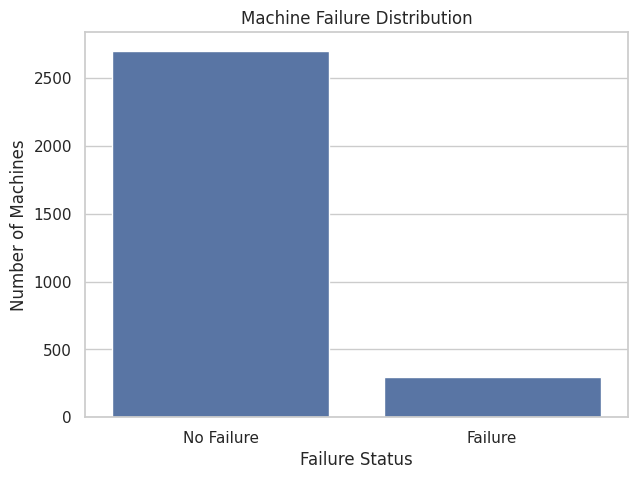

In [83]:
print(df["Failure_Status"].value_counts())
print(
    df["Failure_Status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


# Graph

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Failure_Status"
)

plt.title("Machine Failure Distribution")
plt.xlabel("Failure Status")
plt.ylabel("Number of Machines")
plt.xticks(
    [0, 1],
    ["No Failure", "Failure"]
)

plt.show()

In [84]:
# Select input features

features = [
    "Temperature",
    "Pressure",
    "Vibration_Level",
    "Humidity",
    "Power_Consumption"
]

target = "Failure_Status"

X = df[features]
y = df[target]

print("Features:")
print(features)

print("\nTarget:")
print(target)

Features:
['Temperature', 'Pressure', 'Vibration_Level', 'Humidity', 'Power_Consumption']

Target:
Failure_Status


### Features Distribution

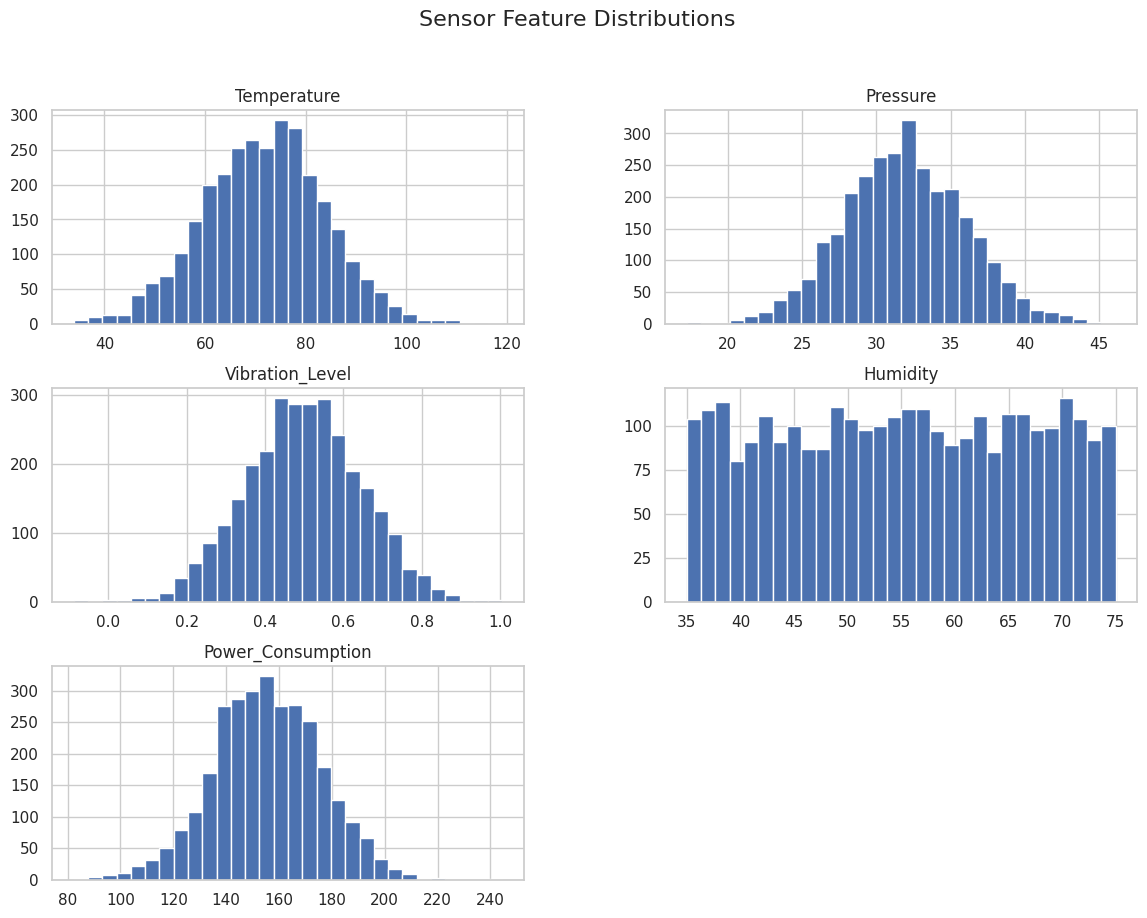

In [85]:
# Distribution of sensor variables

df[features].hist(
    figsize=(14, 10),
    bins=30
)

plt.suptitle("Sensor Feature Distributions", fontsize=16)
plt.xticks(range(60, 130, 10))
plt.show()

### Correlation matrix

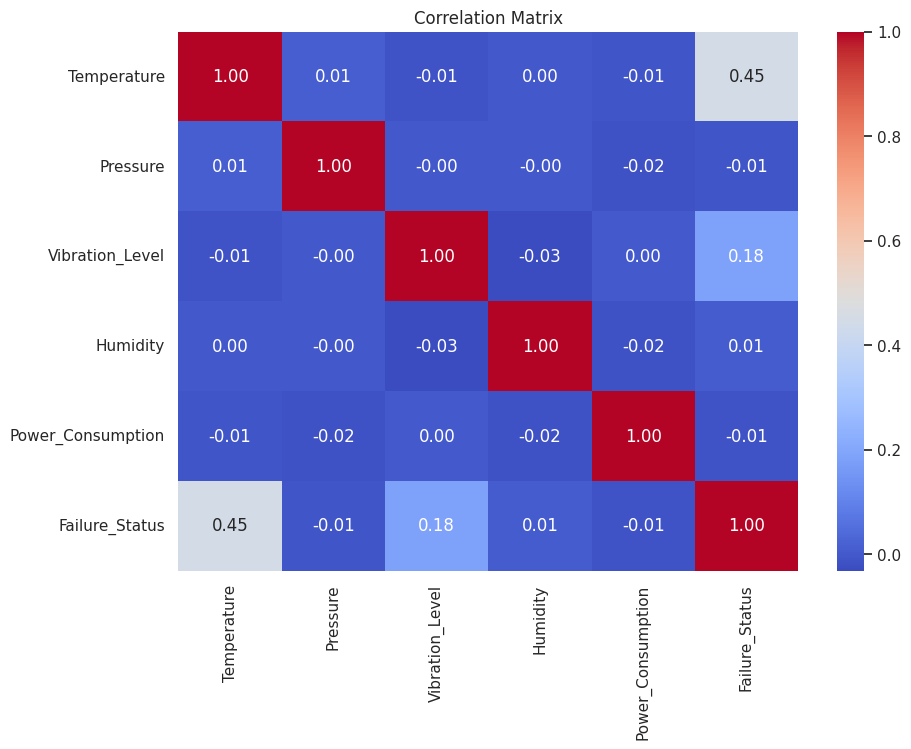

In [86]:
# Correlation matrix

plt.figure(figsize=(10, 7))

correlation = df[features + [target]].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

### Compare sensor averages

In [87]:
# Cell 14: Compare sensor averages

display(
    df.groupby("Failure_Status")[features]
      .mean()
      .round(2)
)

,Temperature,Pressure,Vibration_Level,Humidity,Power_Consumption
Failure_Status,,,,,
0,69.95,31.93,0.49,55.05,155.55
1,87.96,31.81,0.58,55.32,154.62


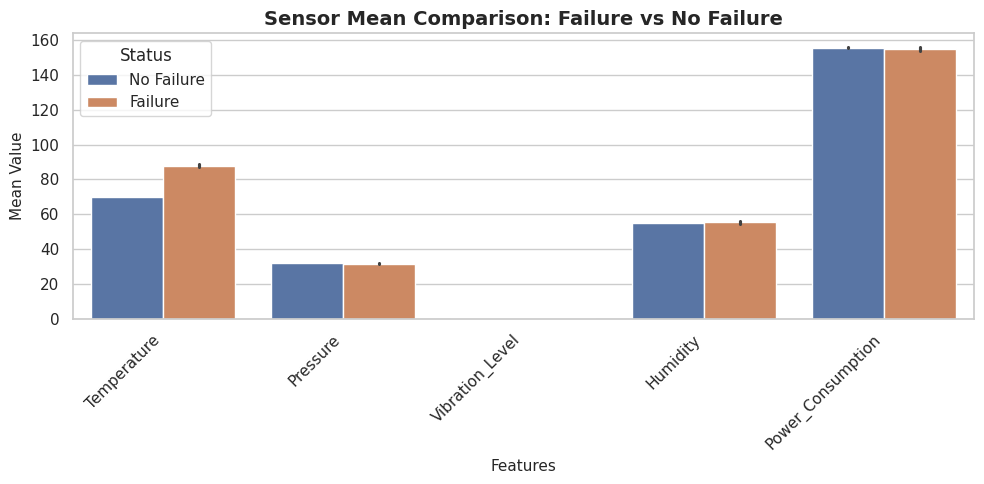

In [88]:
# Reshape dataframe to long format
df_melted = df.melt(
    id_vars=["Failure_Status"],
    value_vars=features,
    var_name="Sensor_Feature",
    value_name="Measurement"
)

plt.figure(figsize=(10, 5))

# Grouped bar chart (mean measurement with 95% CI error bars)
sns.barplot(
    data=df_melted,
    x="Sensor_Feature",
    y="Measurement",
    hue="Failure_Status",
    errorbar="se"  # Displays standard error bars; use None to omit
)

plt.title("Sensor Mean Comparison: Failure vs No Failure", fontsize=14, fontweight="bold")
plt.xlabel("Features", fontsize=11)
plt.ylabel("Mean Value", fontsize=11)
plt.xticks(rotation=45, ha="right")

# Update legend
handles, _ = plt.gca().get_legend_handles_labels()
plt.legend(handles, ["No Failure", "Failure"], title="Status")

plt.tight_layout()
plt.show()

## 3: Train-test split

In [89]:
# !pip install imbalanced-learn

In [90]:
# Features (input variables)
X = df[['Temperature',
        'Pressure',
        'Vibration_Level',
        'Humidity',
        'Power_Consumption']]

# Target (what we want to predict)
y = df['Failure_Status']

print("X shape:", X.shape)
print("y shape:", y.shape)


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X shape: (3000, 5)
y shape: (3000,)


### SMOTE analysis

In [91]:

# SMOTE creates synthetic examples of the minority class (Failure) in the training data.

from imblearn.over_sampling import SMOTE


print("Before SMOTE y_train count:", y_train.value_counts())
print("\nTraining samples before SMOTE:", len(X_train))
print("Testing samples before SMOTE:", len(X_test))

smote = SMOTE(random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train) # SMOTE is applied to only training data.


print("\n\n\nAfter SMOTE y_train count:", y_train.value_counts())
print("\nTraining samples after SMOTE:", len(X_train))
print("Testing samples after SMOTE:", len(X_test))

Before SMOTE y_train count: Failure_Status
0    2162
1     238
Name: count, dtype: int64

Training samples before SMOTE: 2400
Testing samples before SMOTE: 600



After SMOTE y_train count: Failure_Status
0    2162
1    2162
Name: count, dtype: int64

Training samples after SMOTE: 4324
Testing samples after SMOTE: 600


## 4: Logistic Regression

In [92]:
# Logistic Regression

logistic_model = Pipeline([
    ("scaler", StandardScaler()),

    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

logistic_pred = logistic_model.predict(X_test)
logistic_prob = logistic_model.predict_proba(X_test)[:, 1]



# Logistic Regression evaluation

print(f"Recall:    {recall_score(y_test, logistic_pred):.2%}")
print(f"F1 Score:  {f1_score(y_test, logistic_pred):.2%}")
print(f"Precision: {precision_score(y_test, logistic_pred):.2%}")
print(f"Accuracy:  {accuracy_score(y_test, logistic_pred):.2%}")
print(f"ROC-AUC:   {roc_auc_score(y_test, logistic_prob):.2}")

Recall:    89.83%
F1 Score:  52.74%
Precision: 37.32%
Accuracy:  84.17%
ROC-AUC:   0.93


In [93]:
# ============================================================
# FINE-TUNED LOGISTIC REGRESSION
# ============================================================


# ------------------------------------------------------------
# 1. Create Logistic Regression pipeline
# ------------------------------------------------------------

lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000))
])


# ------------------------------------------------------------
# 2. Define hyperparameters to tune
# ------------------------------------------------------------

param_grid = {
    "model__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear", "lbfgs"],
    "model__class_weight": [None, "balanced"]
}


# ------------------------------------------------------------
# 3. Stratified 5-Fold Cross Validation
# ------------------------------------------------------------

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# ------------------------------------------------------------
# 4. Grid Search
# ------------------------------------------------------------

grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)


# ------------------------------------------------------------
# 5. Best model
# ------------------------------------------------------------

best_lr = grid_search.best_estimator_

print("\n" + "=" * 60)
print("BEST LOGISTIC REGRESSION")
print("=" * 60)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(round(grid_search.best_score_, 4))


# ------------------------------------------------------------
# 6. Predictions using default threshold = 0.50
# ------------------------------------------------------------

y_prob = best_lr.predict_proba(X_test)[:, 1]

y_pred_default = (y_prob >= 0.50).astype(int)


# ------------------------------------------------------------
# 7. Evaluate default threshold
# ------------------------------------------------------------

accuracy_default = accuracy_score(y_test, y_pred_default)
precision_default = precision_score(
    y_test, y_pred_default, zero_division=0
)
recall_default = recall_score(
    y_test, y_pred_default, zero_division=0
)
f1_default = f1_score(
    y_test, y_pred_default, zero_division=0
)
roc_auc = roc_auc_score(y_test, y_prob)


print("\n" + "=" * 60)
print("TEST SET RESULTS - DEFAULT THRESHOLD (0.50)")
print("=" * 60)

print(f"Accuracy:  {accuracy_default * 100:.2f}%")
print(f"Precision: {precision_default * 100:.2f}%")
print(f"Recall:    {recall_default * 100:.2f}%")
print(f"F1 Score:  {f1_default * 100:.2f}%")
print(f"ROC-AUC:   {roc_auc * 100:.2f}%")


print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_default,
    target_names=["No Failure", "Failure"],
    zero_division=0
))


# ------------------------------------------------------------
# 8. Threshold tuning
# ------------------------------------------------------------

threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.01):

    y_pred_threshold = (y_prob >= threshold).astype(int)

    precision = precision_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred_threshold,
        zero_division=0
    )

    accuracy = accuracy_score(
        y_test,
        y_pred_threshold
    )

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })


threshold_df = pd.DataFrame(threshold_results)


# ------------------------------------------------------------
# 9. Select threshold with highest F1
# ------------------------------------------------------------

best_threshold_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

best_threshold = best_threshold_row["Threshold"]


print("\n" + "=" * 60)
print("BEST CLASSIFICATION THRESHOLD")
print("=" * 60)

print(f"Best Threshold: {best_threshold:.2f}")
print(f"Accuracy:  {best_threshold_row['Accuracy'] * 100:.2f}%")
print(f"Precision: {best_threshold_row['Precision'] * 100:.2f}%")
print(f"Recall:    {best_threshold_row['Recall'] * 100:.2f}%")
print(f"F1 Score:  {best_threshold_row['F1'] * 100:.2f}%")
print(f"ROC-AUC:   {roc_auc * 100:.2f}%")


# ------------------------------------------------------------
# 10. Final predictions using optimized threshold
# ------------------------------------------------------------

y_pred_tuned = (
    y_prob >= best_threshold
).astype(int)


# ------------------------------------------------------------
# 11. Final evaluation
# ------------------------------------------------------------

final_accuracy = accuracy_score(
    y_test,
    y_pred_tuned
)

final_precision = precision_score(
    y_test,
    y_pred_tuned,
    zero_division=0
)

final_recall = recall_score(
    y_test,
    y_pred_tuned,
    zero_division=0
)

final_f1 = f1_score(
    y_test,
    y_pred_tuned,
    zero_division=0
)


print("\n" + "=" * 60)
print("FINAL TUNED LOGISTIC REGRESSION")
print("=" * 60)

print(f"Threshold: {best_threshold:.2f}")
print(f"Accuracy:  {final_accuracy * 100:.2f}%")
print(f"Precision: {final_precision * 100:.2f}%")
print(f"Recall:    {final_recall * 100:.2f}%")
print(f"F1 Score:  {final_f1 * 100:.2f}%")
print(f"ROC-AUC:   {roc_auc * 100:.2f}%")


print("\nFinal Classification Report:")
print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=["No Failure", "Failure"],
    zero_division=0
))


# ------------------------------------------------------------
# 12. Confusion Matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test,
    y_pred_tuned
)

print("\nConfusion Matrix:")
print(cm)


# ------------------------------------------------------------
# 13. Before vs After comparison
# ------------------------------------------------------------

comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],

    "Before Tuning": [
        accuracy_default,
        precision_default,
        recall_default,
        f1_default,
        roc_auc
    ],

    "After Tuning": [
        final_accuracy,
        final_precision,
        final_recall,
        final_f1,
        roc_auc
    ]
})

# Convert to percentage
comparison["Before Tuning"] = (
    comparison["Before Tuning"] * 100
).round(2)

comparison["After Tuning"] = (
    comparison["After Tuning"] * 100
).round(2)

print("\n" + "=" * 60)
print("BEFORE vs AFTER")
print("=" * 60)

print(comparison.to_string(index=False))


Fitting 5 folds for each of 24 candidates, totalling 120 fits

BEST LOGISTIC REGRESSION
Best Parameters:
{'model__C': 0.001, 'model__class_weight': None, 'model__solver': 'lbfgs'}

Best Cross-Validation F1 Score:
0.8525

TEST SET RESULTS - DEFAULT THRESHOLD (0.50)
Accuracy:  82.17%
Precision: 34.21%
Recall:    88.14%
F1 Score:  49.29%
ROC-AUC:   93.14%

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.98      0.82      0.89       541
     Failure       0.34      0.88      0.49        59

    accuracy                           0.82       600
   macro avg       0.66      0.85      0.69       600
weighted avg       0.92      0.82      0.85       600


BEST CLASSIFICATION THRESHOLD
Best Threshold: 0.57
Accuracy:  91.67%
Precision: 55.29%
Recall:    79.66%
F1 Score:  65.28%
ROC-AUC:   93.14%

FINAL TUNED LOGISTIC REGRESSION
Threshold: 0.57
Accuracy:  91.67%
Precision: 55.29%
Recall:    79.66%
F1 Score:  65.28%
ROC-AUC:   93.14%

Final Classi

## 5: Decision Tree

In [94]:
# Decision Tree

decision_tree = DecisionTreeClassifier(
    max_depth=6,
    class_weight="balanced",
    random_state=42
)

decision_tree.fit(X_train, y_train)

tree_pred = decision_tree.predict(X_test)
tree_prob = decision_tree.predict_proba(X_test)[:, 1]



# Decision Tree evaluation
print(f"Accuracy:  {accuracy_score(y_test, tree_pred):.2%}")
print(f"Precision: {precision_score(y_test, tree_pred):.2%}")
print(f"Recall:    {recall_score(y_test, tree_pred):.2%}")
print(f"F1 Score:  {f1_score(y_test, tree_pred):.2%}")
print(f"ROC-AUC:   {roc_auc_score(y_test, tree_prob):.2}")

Accuracy:  97.00%
Precision: 77.33%
Recall:    98.31%
F1 Score:  86.57%
ROC-AUC:   0.97


In [95]:
# ============================================================
# FAST FINE-TUNED DECISION TREE
# ============================================================

import numpy as np
import pandas as pd
import time

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from scipy.stats import randint


# ============================================================
# 1. BASE DECISION TREE
# ============================================================

decision_tree = DecisionTreeClassifier(
    random_state=42
)


# ============================================================
# 2. SMALL, EFFECTIVE SEARCH SPACE
# ============================================================

param_distributions = {

    "max_depth": randint(3, 16),

    "min_samples_split": randint(2, 31),

    "min_samples_leaf": randint(1, 16),

    "max_features": [
        None,
        "sqrt",
        "log2"
    ],

    "criterion": [
        "gini",
        "entropy",
        "log_loss"
    ]
}


# ============================================================
# 3. 3-FOLD STRATIFIED CV
# ============================================================

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)


# ============================================================
# 4. RANDOMIZED SEARCH
# ============================================================

random_search = RandomizedSearchCV(

    estimator=decision_tree,

    param_distributions=param_distributions,

    # 25 combinations × 3 folds = 75 fits
    n_iter=25,

    scoring="roc_auc",

    cv=cv,

    n_jobs=-1,

    random_state=42,

    verbose=1
)


# ============================================================
# 5. TRAIN
# ============================================================

print("=" * 60)
print("STARTING DECISION TREE HYPERPARAMETER SEARCH")
print("=" * 60)

start_time = time.time()

random_search.fit(
    X_train,
    y_train
)

end_time = time.time()

print("\nTraining completed.")
print(
    f"Time taken: {(end_time - start_time) / 60:.2f} minutes"
)


# ============================================================
# 6. BEST MODEL
# ============================================================

best_tree = random_search.best_estimator_


print("\n" + "=" * 60)
print("BEST DECISION TREE")
print("=" * 60)

print("\nBest Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(
    f"{random_search.best_score_:.4f}"
)


# ============================================================
# 7. TEST SET PREDICTION
# ============================================================

tree_prob = best_tree.predict_proba(
    X_test
)[:, 1]

tree_pred = (
    tree_prob >= 0.50
).astype(int)


# ============================================================
# 8. EVALUATION
# ============================================================

tree_accuracy = accuracy_score(
    y_test,
    tree_pred
)

tree_precision = precision_score(
    y_test,
    tree_pred,
    zero_division=0
)

tree_recall = recall_score(
    y_test,
    tree_pred,
    zero_division=0
)

tree_f1 = f1_score(
    y_test,
    tree_pred,
    zero_division=0
)

tree_roc_auc = roc_auc_score(
    y_test,
    tree_prob
)


# ============================================================
# 9. RESULTS
# ============================================================

print("\n" + "=" * 60)
print("FINE-TUNED DECISION TREE RESULTS")
print("=" * 60)

print(f"Accuracy:  {tree_accuracy:.2%}")
print(f"Precision: {tree_precision:.2%}")
print(f"Recall:    {tree_recall:.2%}")
print(f"F1 Score:  {tree_f1:.2%}")
print(f"ROC-AUC:   {tree_roc_auc:.2%}")

# ============================================================
# 10. CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        tree_pred,
        target_names=[
            "No Failure",
            "Failure"
        ],
        zero_division=0
    )
)


# ============================================================
# 11. CONFUSION MATRIX
# ============================================================

print("\n" + "=" * 60)
print("CONFUSION MATRIX")
print("=" * 60)

print(
    confusion_matrix(
        y_test,
        tree_pred
    )
)


# ============================================================
# 12. FINAL RESULT TABLE
# ============================================================

decision_tree_results = pd.DataFrame(
    {
        "Model": ["Decision Tree"],
        "Accuracy": [tree_accuracy],
        "Precision": [tree_precision],
        "Recall": [tree_recall],
        "F1 Score": [tree_f1],
        "ROC-AUC": [tree_roc_auc],
    }
)

print("\n" + "=" * 60)
print("RESULT TABLE FOR RESEARCH PAPER")
print("=" * 60)

print(
    decision_tree_results.to_string(
        index=False
    )
)

STARTING DECISION TREE HYPERPARAMETER SEARCH
Fitting 3 folds for each of 25 candidates, totalling 75 fits

Training completed.
Time taken: 0.02 minutes

BEST DECISION TREE

Best Parameters:
{'criterion': 'log_loss', 'max_depth': 6, 'max_features': None, 'min_samples_leaf': 15, 'min_samples_split': 12}

Best Cross-Validation ROC-AUC:
0.9912

FINE-TUNED DECISION TREE RESULTS
Accuracy:  97.67%
Precision: 80.82%
Recall:    100.00%
F1 Score:  89.39%
ROC-AUC:   99.02%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  No Failure       1.00      0.97      0.99       541
     Failure       0.81      1.00      0.89        59

    accuracy                           0.98       600
   macro avg       0.90      0.99      0.94       600
weighted avg       0.98      0.98      0.98       600


CONFUSION MATRIX
[[527  14]
 [  0  59]]

RESULT TABLE FOR RESEARCH PAPER
        Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
Decision Tree  0.976667   0.808219     1.0  0.8

## 6: Random Forest

In [96]:
random_forest = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
) # default threshold id 0.5

random_forest.fit(X_train, y_train)

rf_pred = random_forest.predict(X_test)

print('Random Forest : ')
print(f"Recall:    {recall_score(y_test, rf_pred):.2%}")
print(f"F1:        {f1_score(y_test, rf_pred):.2%}")
print(f"Precision: {precision_score(y_test, rf_pred):.2%}")
print(f"Accuracy:  {accuracy_score(y_test, rf_pred):.2}") # ideal = 1


Random Forest : 
Recall:    100.00%
F1:        90.08%
Precision: 81.94%
Accuracy:  0.98


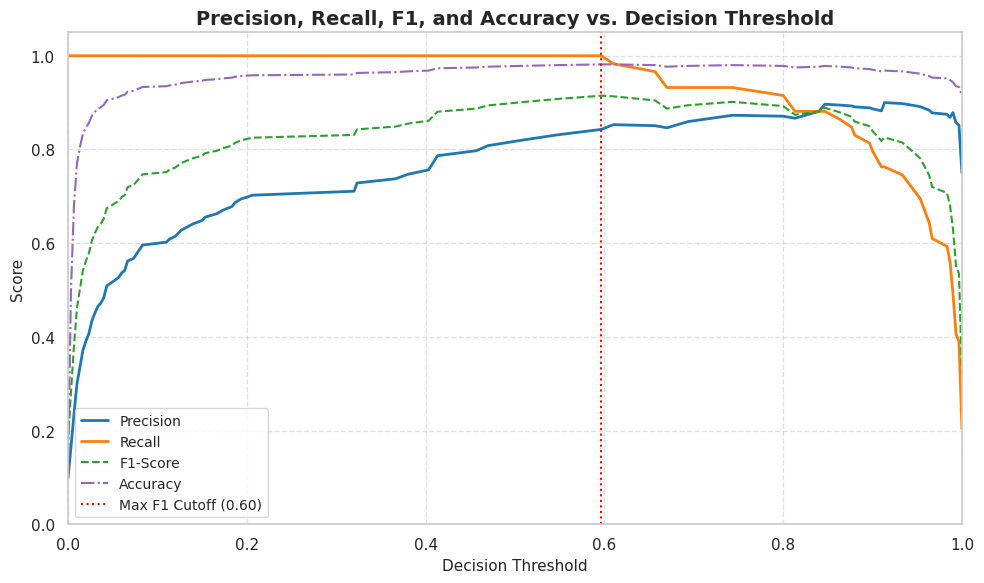

Optimal Threshold (by F1-score): 0.5967
At this threshold -> Accuracy: 98.17%, Precision: 84.29%, Recall: 100.00%, F1: 91.47%


In [97]:
# visualize the Precision-Recall curve to find the optimal threshold

# 1. Obtain predicted probabilities for class 1 (Failure)
rf_prob = random_forest.predict_proba(X_test)[:, 1]

# 2. Compute precision, recall, and corresponding thresholds
precisions, recalls, thresholds = precision_recall_curve(y_test, rf_prob)

# 3. Calculate F1-score across all thresholds
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-8)

# 4. Compute accuracy for each threshold value
accuracies = [accuracy_score(y_test, (rf_prob >= t).astype(int)) for t in thresholds]

# Find best threshold according to F1-score
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

# 5. Plot all 4 metrics vs. Threshold
plt.figure(figsize=(10, 6))

plt.plot(thresholds, precisions[:-1], label="Precision", color="#1f77b4", linewidth=2)
plt.plot(thresholds, recalls[:-1], label="Recall", color="#ff7f0e", linewidth=2)
plt.plot(thresholds, f1_scores, label="F1-Score", color="#2ca02c", linestyle="--", linewidth=1.5)
plt.plot(thresholds, accuracies, label="Accuracy", color="#9467bd", linestyle="-.", linewidth=1.5)

# Highlight optimal F1 cutoff
plt.axvline(
    best_threshold,
    color="red",
    linestyle=":",
    label=f"Max F1 Cutoff ({best_threshold:.2f})"
)

plt.title("Precision, Recall, F1, and Accuracy vs. Decision Threshold", fontsize=14, fontweight="bold")
plt.xlabel("Decision Threshold", fontsize=11)
plt.ylabel("Score", fontsize=11)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(loc="lower left", fontsize=10)

plt.tight_layout()
plt.show()

print(f"Optimal Threshold (by F1-score): {best_threshold:.4f}")
print(f"At this threshold -> Accuracy: {accuracies[best_idx]:.2%}, Precision: {precisions[best_idx]:.2%}, Recall: {recalls[best_idx]:.2%}, F1: {f1_scores[best_idx]:.2%}")

In [98]:
rf_prob = random_forest.predict_proba(X_test)[:, 1]
threshold = 0.35
y_pred_threshold = (rf_prob >= threshold).astype(int)

print('Random Forest : ')
print(f"Recall:    {recall_score(y_test, y_pred_threshold):.2%}")
print(f"F1:        {f1_score(y_test, y_pred_threshold):.2%}")
print(f"Precision: {precision_score(y_test, y_pred_threshold):.2%}")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_threshold):.2%}")


Random Forest : 
Recall:    100.00%
F1:        84.89%
Precision: 73.75%
Accuracy:  96.50%


## 7: Gradient Boosting

In [99]:
# Gradient Boosting

gradient_model = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gradient_model.fit(X_train, y_train)

gradient_pred = gradient_model.predict(X_test)
gradient_prob = gradient_model.predict_proba(X_test)[:, 1]


# Gradient Boosting evaluation
print('Gradient Boosting evaluation')
print(f"Accuracy:  {accuracy_score(y_test, gradient_pred):.2%}")
print(f"Precision: {precision_score(y_test, gradient_pred):.2%}")
print(f"Recall:    {recall_score(y_test, gradient_pred):.2%}")
print(f"F1 Score:  {f1_score(y_test, gradient_pred):.2%}")
print(f"ROC-AUC:   {roc_auc_score(y_test, gradient_prob):.2}")

Gradient Boosting evaluation
Accuracy:  97.33%
Precision: 80.28%
Recall:    96.61%
F1 Score:  87.69%
ROC-AUC:   0.99


STARTING GRADIENT BOOSTING HYPERPARAMETER SEARCH
Fitting 3 folds for each of 25 candidates, totalling 75 fits

Training completed.
Time taken: 1.70 minutes

BEST PARAMETERS
{'learning_rate': np.float64(0.012413189635294229), 'max_depth': 4, 'max_features': 'sqrt', 'min_samples_leaf': 8, 'min_samples_split': 6, 'n_estimators': 198, 'subsample': np.float64(0.8773893363123181)}

Best Cross-Validation ROC-AUC:
0.9953

GRADIENT BOOSTING — THRESHOLD 0.50
Accuracy    : 97.83%
Precision   : 81.94%
Recall      : 100.00%
F1 Score    : 90.08%
ROC-AUC     : 99.13%

BEST THRESHOLD BASED ON F1 SCORE
Best Threshold: 0.60
Accuracy : 98.50%
Precision: 86.76%
Recall   : 100.00%
F1 Score : 92.91%

FINAL GRADIENT BOOSTING RESULTS
Accuracy    : 98.50%
Precision   : 86.76%
Recall      : 100.00%
F1 Score    : 92.91%
ROC-AUC     : 99.13%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

  No Failure       1.00      0.98      0.99       541
     Failure       0.87      1.00      0.9

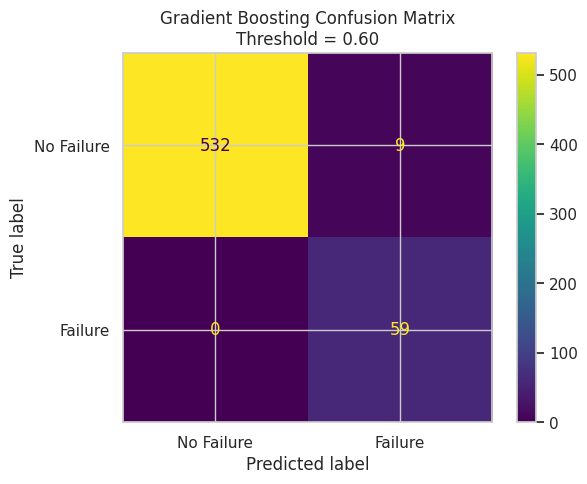


FEATURE IMPORTANCE
             Feature  Importance
0        Temperature    0.731223
2    Vibration_Level    0.250709
4  Power_Consumption    0.009456
1           Pressure    0.005551
3           Humidity    0.003061


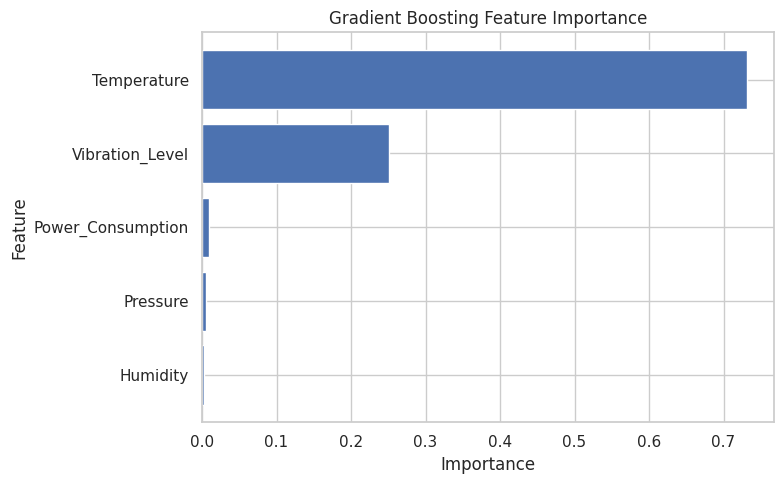

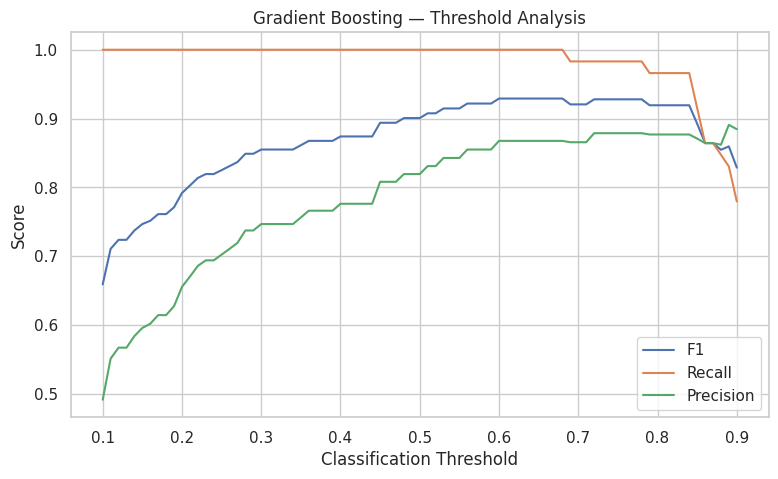


RESULT TABLE FOR RESEARCH PAPER
            Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC  Threshold
Gradient Boosting     0.985   0.867647     1.0  0.929134 0.991337        0.6


In [100]:
# ============================================================
# GRADIENT BOOSTING — HYPERPARAMETER TUNING
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from scipy.stats import randint, loguniform, uniform
import time


# ============================================================
# 1. CREATE BASE MODEL
# ============================================================

gradient_model = GradientBoostingClassifier(
    random_state=42
)


# ============================================================
# 2. HYPERPARAMETER SEARCH SPACE
# ============================================================

param_distributions = {

    # Number of boosting trees
    "n_estimators": randint(100, 401),

    # Learning rate
    "learning_rate": loguniform(0.01, 0.30),

    # Maximum depth of individual trees
    "max_depth": randint(2, 6),

    # Minimum samples required to split
    "min_samples_split": randint(2, 21),

    # Minimum samples in leaf
    "min_samples_leaf": randint(1, 11),

    # Fraction of samples used for each boosting stage
    "subsample": uniform(0.70, 0.30),

    # Number of features considered for splitting
    "max_features": [None, "sqrt", "log2"]
}


# ============================================================
# 3. STRATIFIED CROSS-VALIDATION
# ============================================================

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)


# ============================================================
# 4. RANDOMIZED SEARCH
# ============================================================

random_search = RandomizedSearchCV(
    estimator=gradient_model,
    param_distributions=param_distributions,

    # 25 combinations × 3 folds = 75 model fits
    n_iter=25,

    scoring="roc_auc",
    cv=cv,

    # Use all available CPU cores
    n_jobs=-1,

    random_state=42,
    verbose=1,

    # Not required for our analysis
    return_train_score=False
)


# ============================================================
# 5. TRAIN
# ============================================================

print("=" * 60)
print("STARTING GRADIENT BOOSTING HYPERPARAMETER SEARCH")
print("=" * 60)

start_time = time.time()

random_search.fit(X_train, y_train)

end_time = time.time()

print("\nTraining completed.")
print(f"Time taken: {(end_time - start_time) / 60:.2f} minutes")


# ============================================================
# 6. BEST PARAMETERS
# ============================================================

print("\n" + "=" * 60)
print("BEST PARAMETERS")
print("=" * 60)

print(random_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(f"{random_search.best_score_:.4f}")


# ============================================================
# 7. BEST MODEL
# ============================================================

best_gradient_model = random_search.best_estimator_


# ============================================================
# 8. PREDICT PROBABILITIES
# ============================================================

y_prob = best_gradient_model.predict_proba(X_test)[:, 1]


# ============================================================
# 9. DEFAULT THRESHOLD = 0.50
# ============================================================

threshold_default = 0.50

y_pred_default = (
    y_prob >= threshold_default
).astype(int)


# ============================================================
# 10. FUNCTION FOR METRICS
# ============================================================

def calculate_metrics(y_true, y_pred, y_probability):

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )
    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )
    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )
    roc_auc = roc_auc_score(
        y_true,
        y_probability
    )

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    }


# ============================================================
# 11. DEFAULT THRESHOLD RESULTS
# ============================================================

default_metrics = calculate_metrics(
    y_test,
    y_pred_default,
    y_prob
)

print("\n" + "=" * 60)
print("GRADIENT BOOSTING — THRESHOLD 0.50")
print("=" * 60)

for metric, value in default_metrics.items():
    print(f"{metric:<12}: {value * 100:.2f}%")


# ============================================================
# 12. THRESHOLD OPTIMIZATION
# ============================================================
#
# We test thresholds from 0.10 to 0.90.
#
# IMPORTANT:
# Threshold changes:
# Accuracy
# Precision
# Recall
# F1
#
# Threshold DOES NOT change ROC-AUC.
# ============================================================

thresholds = np.arange(
    0.10,
    0.91,
    0.01
)

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (
        y_prob >= threshold
    ).astype(int)

    threshold_results.append({

        "Threshold": threshold,

        "Accuracy": accuracy_score(
            y_test,
            y_pred_threshold
        ),

        "Precision": precision_score(
            y_test,
            y_pred_threshold,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            y_pred_threshold,
            zero_division=0
        ),

        "F1": f1_score(
            y_test,
            y_pred_threshold,
            zero_division=0
        )
    })


threshold_df = pd.DataFrame(
    threshold_results
)


# ============================================================
# 13. FIND BEST THRESHOLD BASED ON F1
# ============================================================

best_threshold_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

best_threshold = best_threshold_row["Threshold"]


print("\n" + "=" * 60)
print("BEST THRESHOLD BASED ON F1 SCORE")
print("=" * 60)

print(
    f"Best Threshold: {best_threshold:.2f}"
)

print(
    f"Accuracy : {best_threshold_row['Accuracy'] * 100:.2f}%"
)

print(
    f"Precision: {best_threshold_row['Precision'] * 100:.2f}%"
)

print(
    f"Recall   : {best_threshold_row['Recall'] * 100:.2f}%"
)

print(
    f"F1 Score : {best_threshold_row['F1'] * 100:.2f}%"
)


# ============================================================
# 14. FINAL PREDICTIONS USING BEST THRESHOLD
# ============================================================

y_pred_final = (
    y_prob >= best_threshold
).astype(int)


# ============================================================
# 15. FINAL METRICS
# ============================================================

final_metrics = calculate_metrics(
    y_test,
    y_pred_final,
    y_prob
)


print("\n" + "=" * 60)
print("FINAL GRADIENT BOOSTING RESULTS")
print("=" * 60)

for metric, value in final_metrics.items():
    print(f"{metric:<12}: {value * 100:.2f}%")


# ============================================================
# 16. CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred_final,
        target_names=[
            "No Failure",
            "Failure"
        ],
        zero_division=0
    )
)


# ============================================================
# 17. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_pred_final
)

print("\n" + "=" * 60)
print("CONFUSION MATRIX")
print("=" * 60)

print(cm)


# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "No Failure",
        "Failure"
    ]
)

disp.plot()
plt.title(
    f"Gradient Boosting Confusion Matrix\n"
    f"Threshold = {best_threshold:.2f}"
)
plt.show()


# ============================================================
# 18. FEATURE IMPORTANCE
# ============================================================

feature_importance = pd.DataFrame({

    "Feature": X_train.columns,

    "Importance": (
        best_gradient_model
        .feature_importances_
    )

}).sort_values(
    "Importance",
    ascending=False
)


print("\n" + "=" * 60)
print("FEATURE IMPORTANCE")
print("=" * 60)

print(feature_importance)


# Plot feature importance
plt.figure(figsize=(8, 5))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Gradient Boosting Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()
print()


# ============================================================
# 19. THRESHOLD vs F1 / RECALL / PRECISION
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1"],
    label="F1"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")

plt.title(
    "Gradient Boosting — Threshold Analysis"
)

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# 20. SAVE RESULTS FOR PAPER
# ============================================================

gradient_results = pd.DataFrame({

    "Model": [
        "Gradient Boosting"
    ],

    "Accuracy": [
        final_metrics["Accuracy"]
    ],

    "Precision": [
        final_metrics["Precision"]
    ],

    "Recall": [
        final_metrics["Recall"]
    ],

    "F1 Score": [
        final_metrics["F1 Score"]
    ],

    "ROC-AUC": [
        final_metrics["ROC-AUC"]
    ],

    "Threshold": [
        best_threshold
    ]
})


print("\n" + "=" * 60)
print("RESULT TABLE FOR RESEARCH PAPER")
print("=" * 60)

print(
    gradient_results.to_string(
        index=False
    )
)

## 8: Compare models

In [101]:
# Compare models

results = []

models_predictions = [
    ("Logistic Regression", logistic_pred, logistic_prob),
    ("Decision Tree", tree_pred, tree_prob),
    ("Random Forest", rf_pred, rf_prob),
    ("Gradient Boosting", gradient_pred, gradient_prob)
]

for name, predictions, probabilities in models_predictions:

    results.append({
        "Model": name,

        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),

        "Precision": precision_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "F1 Score": f1_score(
            y_test,
            predictions,
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_test,
            probabilities
        )
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "F1 Score",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,Random Forest,0.978333,0.819444,1.000000,0.900763,0.991337
1,Decision Tree,0.976667,0.808219,1.000000,0.893939,0.990225
3,Gradient Boosting,0.973333,0.802817,0.966102,0.876923,0.988439
0,Logistic Regression,0.841667,0.373239,0.898305,0.527363,0.928068


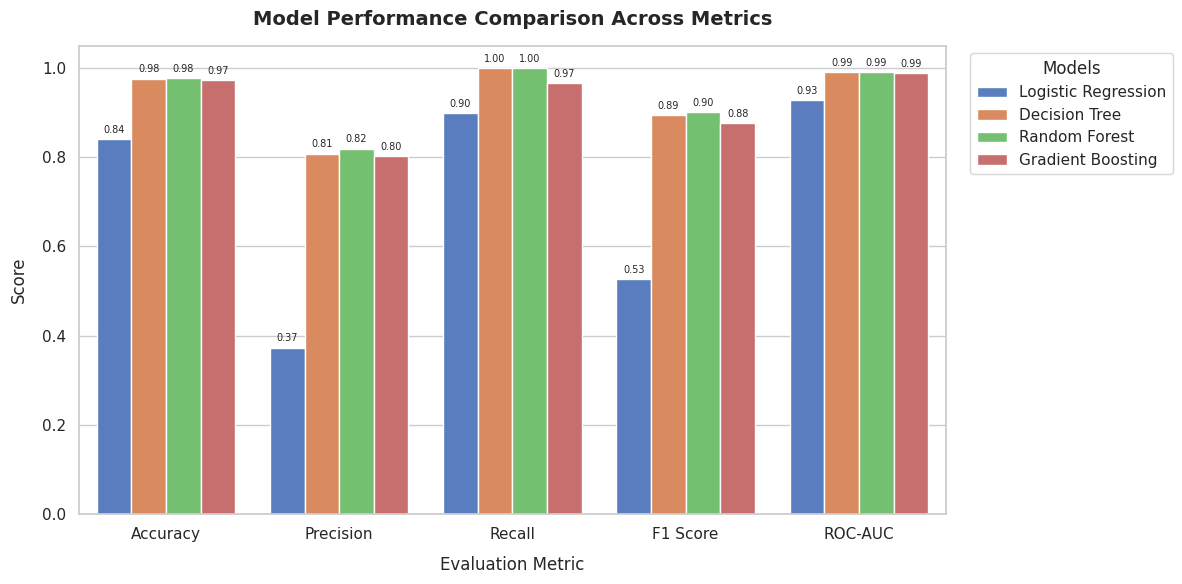

In [102]:
# Set style for cleaner visualization
sns.set_theme(style="whitegrid")

# Melt the DataFrame so Metrics are on the x-axis and Models are the legend groups
melted_df = results_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"],
    var_name="Metric",
    value_name="Score",
)

# Initialize figure
plt.figure(figsize=(12, 6))

# Create multi-bar chart with Metrics on x-axis and Models as hue (legend)
ax = sns.barplot(
    data=melted_df, x="Metric", y="Score", hue="Model", palette="muted"
)

# Customize chart labels and title
plt.title(
    "Model Performance Comparison Across Metrics", fontsize=14, fontweight="bold", pad=15
)
plt.xlabel("Evaluation Metric", fontsize=12, labelpad=10)
plt.ylabel("Score", fontsize=12, labelpad=10)
plt.ylim(0, 1.05)  # Setting y-axis limit from 0 to 1 (with slight headroom)

# Place legend outside or neatly inside
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Models")

# Add value annotations on top of the bars
for p in ax.patches:
    height = p.get_height()
    if height > 0:  # Avoid labeling zero/empty bars
        ax.annotate(
            f"{height:.2f}",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=7,
            rotation=0,
            xytext=(0, 3),
            textcoords="offset points",
        )

plt.tight_layout()
plt.show()

### Select best model

In [103]:
# Select best model

best_model_name = (
    results_df
    .sort_values(
        ["F1 Score", "Recall", "ROC-AUC"],
        ascending=False
    )
    .iloc[0]["Model"]
)

print("Best model:", best_model_name)

Best model: Random Forest


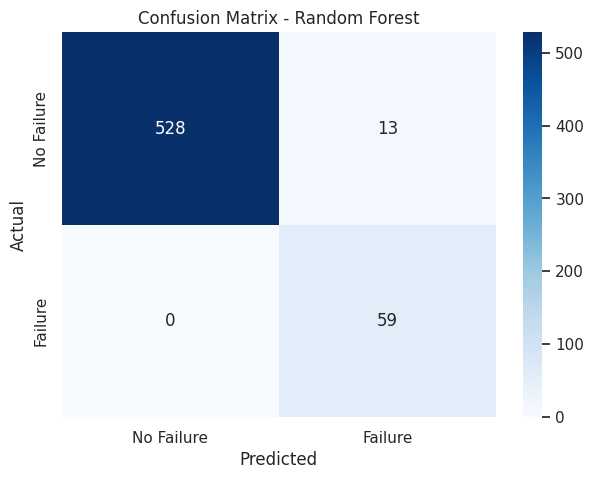

In [104]:
# Select predictions for best model

prediction_dictionary = {
    "Logistic Regression": logistic_pred,
    "Decision Tree": tree_pred,
    "Random Forest": rf_pred,
    "Gradient Boosting": gradient_pred
}

best_predictions = prediction_dictionary[best_model_name]

cm = confusion_matrix(
    y_test,
    best_predictions
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title(
    f"Confusion Matrix - {best_model_name}"
)

plt.show()

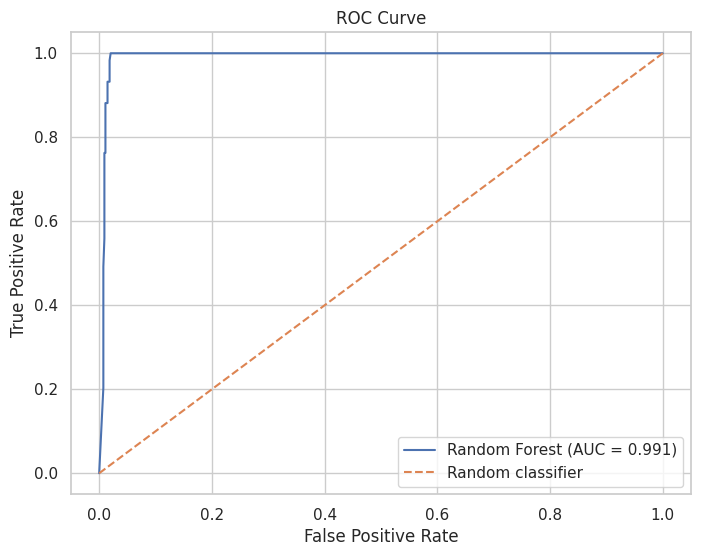

In [105]:
# ROC Curve

probability_dictionary = {
    "Logistic Regression": logistic_prob,
    "Decision Tree": tree_prob,
    "Random Forest": rf_prob,
    "Gradient Boosting": gradient_prob
}

best_probability = probability_dictionary[best_model_name]

fpr, tpr, thresholds = roc_curve(
    y_test,
    best_probability
)

auc_score = roc_auc_score(
    y_test,
    best_probability
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"{best_model_name} (AUC = {auc_score:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.show()

## 9: Feature importance of best model

,Feature,Importance
0,Temperature,0.700119
2,Vibration_Level,0.243168
4,Power_Consumption,0.022962
1,Pressure,0.018779
3,Humidity,0.014972


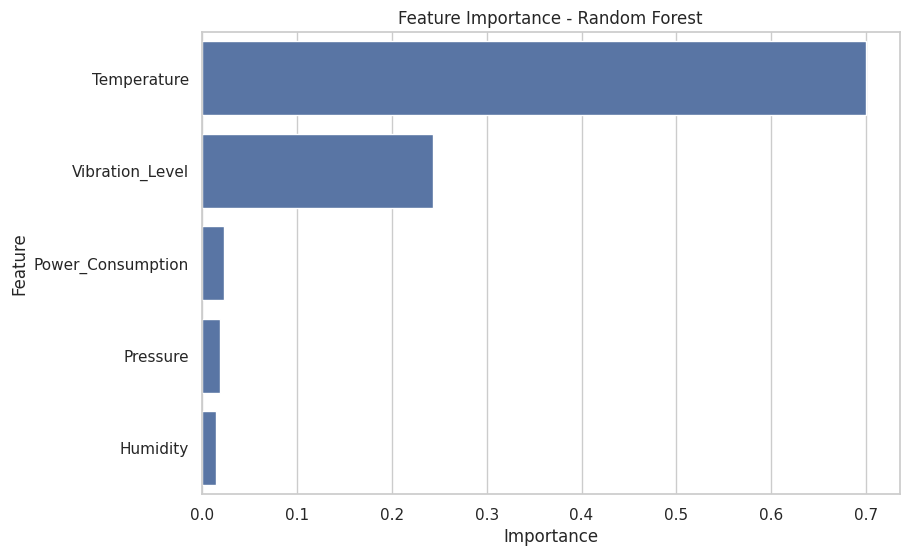

In [106]:
# Feature importance

if best_model_name == "Random Forest":
    importance = random_forest.feature_importances_
    features = X_train.columns

elif best_model_name == "Gradient Boosting":
    importance = gradient_model.feature_importances_
    features = X_train.columns

elif best_model_name == "Logistic Regression":
    importance = logistic_model.named_steps["model"].coef_[0]
    features = X_train.columns

else:
    importance = None


if importance is not None:

    feature_importance = pd.DataFrame({
        "Feature": features,
        "Importance": importance
    }).sort_values(
        "Importance",
        ascending=False
    )

    display(feature_importance)

    plt.figure(figsize=(9, 6))

    sns.barplot(
        data=feature_importance,
        x="Importance",
        y="Feature"
    )

    plt.title(
        f"Feature Importance - {best_model_name}"
    )

    plt.show()

else:

    print(
        "Feature importance for Logistic Regression "
        "will be calculated using model coefficients."
    )

In [107]:
# Logistic Regression coefficients

coefficients = logistic_model.named_steps["model"].coef_[0]

logistic_importance = pd.DataFrame({
    "Feature": features,
    "Coefficient": coefficients,
    "Absolute Importance": np.round(np.abs(coefficients), decimals=0)
}).sort_values(
    "Absolute Importance",
    ascending=False
)

display(logistic_importance)

,Feature,Coefficient,Absolute Importance
0,Temperature,2.787924,3.0
2,Vibration_Level,1.540065,2.0
1,Pressure,-0.020929,0.0
3,Humidity,-0.003515,0.0
4,Power_Consumption,0.029757,0.0


## 10: Machine failure prediction function

In [108]:
# Machine failure prediction function

model_dictionary = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree,
    "Random Forest": random_forest,
    "Gradient Boosting": gradient_model
}

best_model = model_dictionary[best_model_name]


def predict_machine_failure(
    temperature,
    pressure,
    vibration,
    humidity,
    power
):

    input_data = pd.DataFrame({
        "Temperature": [temperature],
        "Pressure": [pressure],
        "Vibration_Level": [vibration],
        "Humidity": [humidity],
        "Power_Consumption": [power]
    })

    prediction = best_model.predict(
        input_data
    )[0]

    probability = best_model.predict_proba(
        input_data
    )[0][1]

    if prediction == 1:
        status = "⚠️ FAILURE"
    else:
        status = "✅ NO FAILURE"

    print("Machine Prediction")
    print("------------------")
    print("Status:", status)
    print(
        f"Failure Probability: {probability * 100:.2f}%"
    )

    return prediction, probability

## 11: Test prediction

In [109]:
# Test prediction

prediction, probability = predict_machine_failure(
    temperature=82,
    pressure=101,
    vibration=7.4,
    humidity=78,
    power=9.5
)

Machine Prediction
------------------
Status: ⚠️ FAILURE
Failure Probability: 68.00%


In [110]:
# Another prediction

predict_machine_failure(
    temperature=65,
    pressure=95,
    vibration=2.5,
    humidity=45,
    power=5.0
)

Machine Prediction
------------------
Status: ⚠️ FAILURE
Failure Probability: 82.33%


(np.int64(1), np.float64(0.8233333333333334))

## 12: Save model

In [111]:
# Save and Load the saved model

import joblib

joblib.dump(
    best_model,
    "machine_failure_model.pkl"
)

print("Model saved successfully!")


loaded_model = joblib.load(
    "machine_failure_model.pkl"
)

print("Model loaded successfully!")

Model saved successfully!
Model loaded successfully!


## 13: Final model summary

In [112]:
# Final model summary

best_row = results_df[
    results_df["Model"] == best_model_name
].iloc[0]

print("=" * 50)
print("MACHINE FAILURE PREDICTION MODEL")
print("=" * 50)

print("\nBest Model:", best_model_name)
print(f"Accuracy : {best_row['Accuracy']*100:.2f}%")
print(f"Precision: {best_row['Precision']*100:.2f}%")
print(f"Recall   : {best_row['Recall']*100:.2f}%")
print(f"F1 Score : {best_row['F1 Score']*100:.2f}%")
print(f"ROC-AUC  : {best_row['ROC-AUC']*100:.2f}%")


print("\nTarget:")
print("0 = No Failure")
print("1 = Failure")

print("\nInput Sensors:")
for feature in features:
    print("-", feature)

MACHINE FAILURE PREDICTION MODEL

Best Model: Random Forest
Accuracy : 97.83%
Precision: 81.94%
Recall   : 100.00%
F1 Score : 90.08%
ROC-AUC  : 99.13%

Target:
0 = No Failure
1 = Failure

Input Sensors:
- Temperature
- Pressure
- Vibration_Level
- Humidity
- Power_Consumption
